In [1]:
import pandas as pd
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import accuracy_score, classification_report, f1_score

In [2]:
df = pd.read_csv("../Data/groceries.csv")

df = df[['Score', 'Text']]
df = df.dropna()

df.head()

,Score,Text
0,5,I have bought several of the Vitality canned d...
1,1,Product arrived labeled as Jumbo Salted Peanut...
2,4,This is a confection that has been around a fe...
3,2,If you are looking for the secret ingredient i...
4,5,Great taffy at a great price. There was a wid...


In [3]:
def convert_sentiment(score):
    if score <= 2:
        return 0   # Negative
    elif score == 3:
        return 1   # Neutral
    else:
        return 2   # Positive

df['Sentiment'] = df['Score'].apply(convert_sentiment)

df[['Score', 'Sentiment']].head()

,Score,Sentiment
0,5,2
1,1,0
2,4,2
3,2,0
4,5,2


In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df['Text'] = df['Text'].apply(clean_text)

In [5]:
df = df.sample(10000, random_state=42)
df.shape

(10000, 3)

In [6]:
vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(df['Text'])
y = df['Sentiment']

In [7]:
vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(df['Text'])
y = df['Sentiment']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
models = {

    "Logistic Regression":
    LogisticRegression(max_iter=1000),

    "Naive Bayes":
    MultinomialNB(),

    "SVM":
    LinearSVC(),

    "Random Forest":
    RandomForestClassifier(),

    "SGD":
    SGDClassifier(),

    "Bagging":
    BaggingClassifier()
}


for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(name)

    print(
        "Accuracy:",
        accuracy_score(y_test, y_pred)
    )

    print("-------------------")

Logistic Regression
Accuracy: 0.8235
-------------------
Naive Bayes
Accuracy: 0.778
-------------------
SVM
Accuracy: 0.832
-------------------
Random Forest
Accuracy: 0.794
-------------------
SGD
Accuracy: 0.8325
-------------------
Bagging
Accuracy: 0.7965
-------------------


In [10]:
base_models = [
    ("lr", LogisticRegression(max_iter=1000)),
    ("nb", MultinomialNB()),
    ("svm", LinearSVC())
]

meta_model = LogisticRegression()

stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model
)

stack_model.fit(X_train, y_train)

,estimators,"[('lr', ...), ('nb', ...), ...]"
,final_estimator,LogisticRegression()
,cv,None
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [11]:
base_models = [

    ("lr", LogisticRegression(max_iter=1000)),

    ("nb", MultinomialNB()),

    ("svm", LinearSVC()),

    ("rf", RandomForestClassifier()),

    ("sgd", SGDClassifier()),

    ("bag", BaggingClassifier())

]

meta_model = LogisticRegression()

stack_model = StackingClassifier(

    estimators=base_models,

    final_estimator=meta_model

)

stack_model.fit(X_train, y_train)

print("Stacking Model Trained Successfully")

Stacking Model Trained Successfully


In [12]:
y_pred = stack_model.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        y_pred,
        average='macro'
    )
)

print(
    "Weighted F1:",
    f1_score(
        y_test,
        y_pred,
        average='weighted'
    )
)

Accuracy: 0.8385

Classification Report:

              precision    recall  f1-score   support

           0       0.67      0.59      0.63       298
           1       0.40      0.09      0.15       152
           2       0.87      0.96      0.91      1550

    accuracy                           0.84      2000
   macro avg       0.65      0.55      0.56      2000
weighted avg       0.81      0.84      0.81      2000

Macro F1: 0.5636208624828026
Weighted F1: 0.813669994415569


In [13]:
sample = ["this product is not good and poor quality"]

sample_vec = vectorizer.transform(sample)

prediction = stack_model.predict(sample_vec)

prediction


array([0])

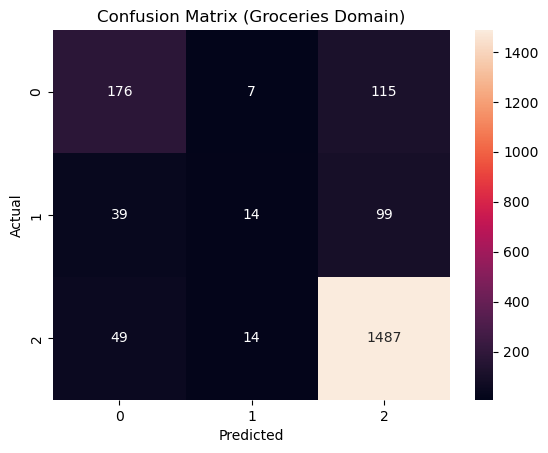

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions from stacking model
y_pred = stack_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix (Groceries Domain)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [15]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable


In [16]:
import shap
shap.initjs()

In [17]:
from sklearn.linear_model import LogisticRegression

shap_model = LogisticRegression(max_iter=1000)
shap_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [18]:
explainer = shap.Explainer(shap_model, X_train)

In [19]:
shap_values = explainer(X_test[:100])

In [20]:
# Convert to dense (IMPORTANT)
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()

# Train model again
shap_model = LogisticRegression(max_iter=1000)
shap_model.fit(X_train_dense, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [21]:
explainer = shap.Explainer(shap_model, X_train_dense)

In [22]:
shap_values = explainer(X_test_dense[:100])

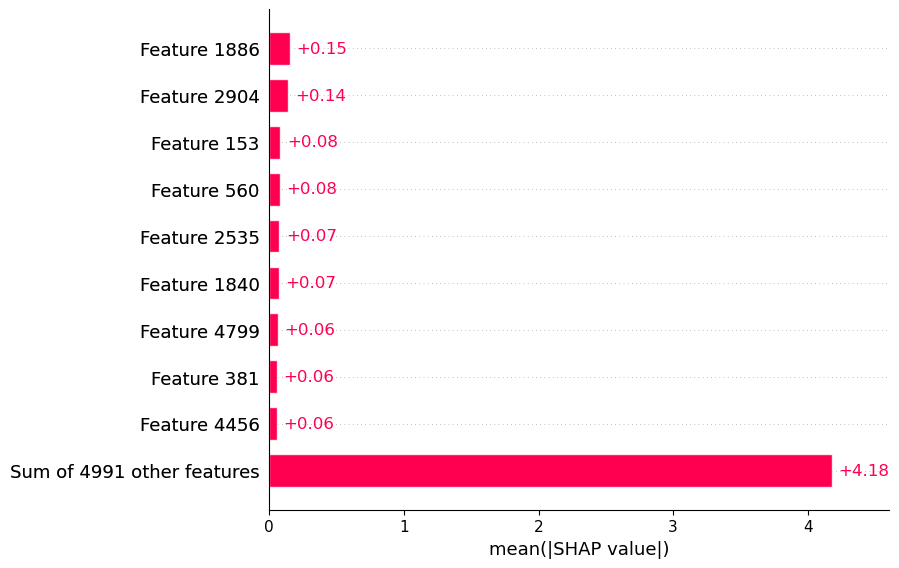

In [23]:
shap.plots.bar(shap_values[:, :, 2])

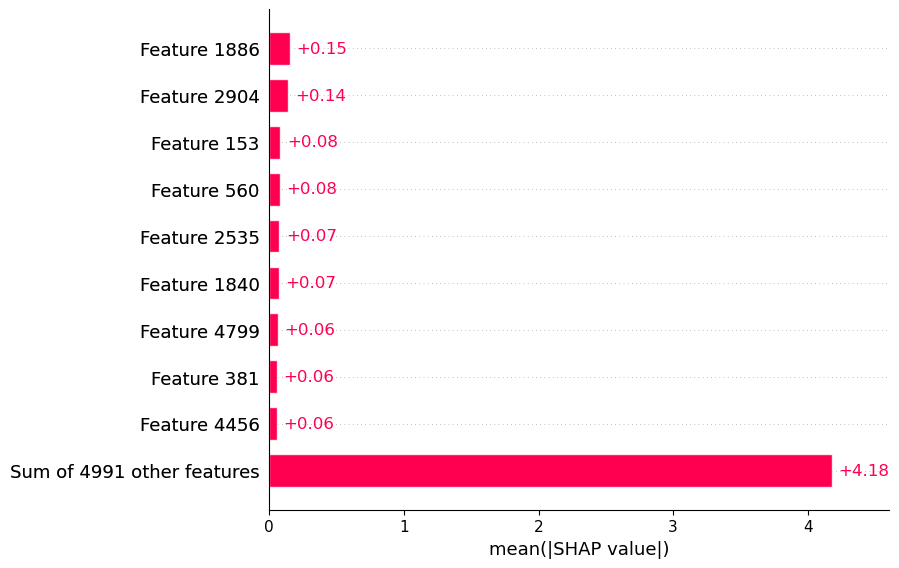

In [24]:
shap.plots.bar(shap_values[:, :, 2])

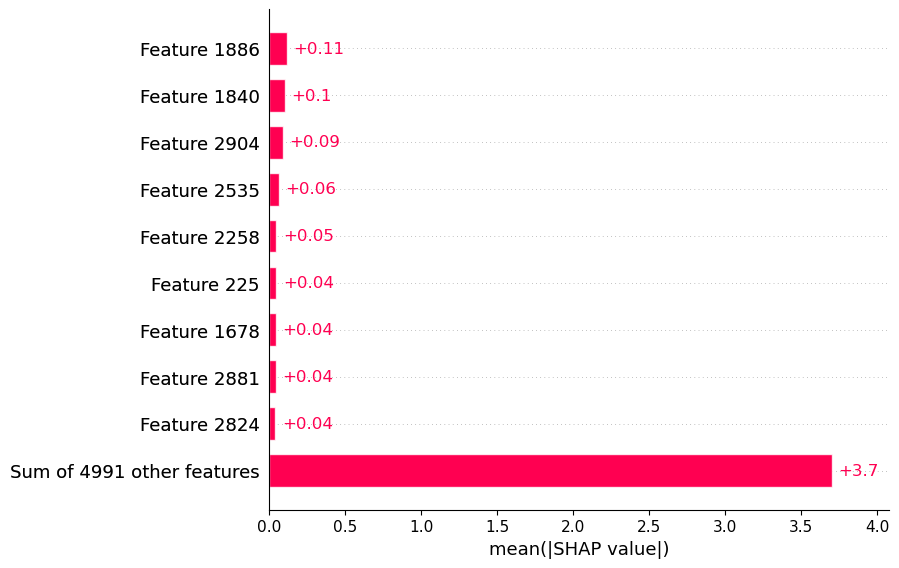

In [25]:
shap.plots.bar(shap_values[:, :, 0])

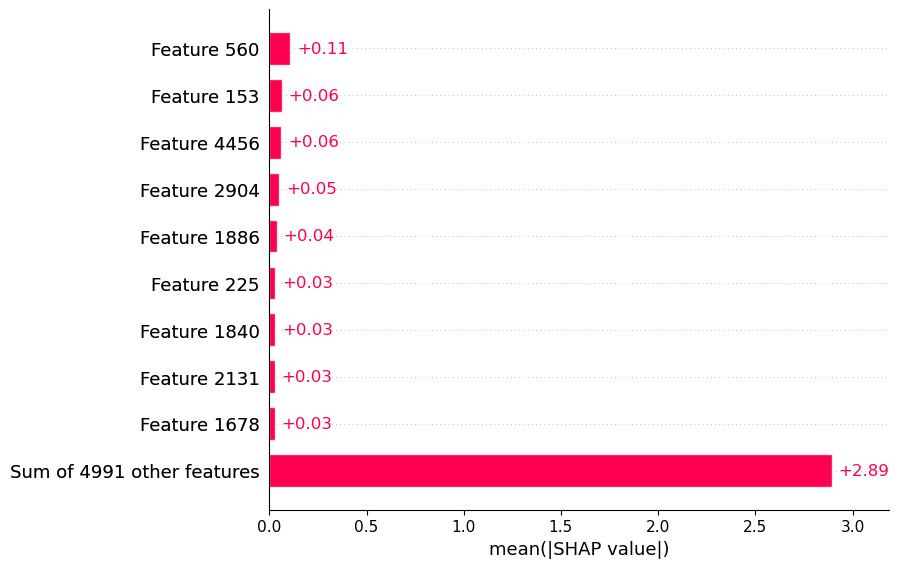

In [26]:
shap.plots.bar(shap_values[:, :, 1])